In [1]:
import sys
import os
import pickle
from typing import NamedTuple
import math
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_worm import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
ll = 'll00'
data_variants = [
	'gcamp',
	'gfp',
	'art',
]
model_variant = 'ns'
organism = 'worm-2025-fieseler'

In [4]:
if 'gcamp' in data_variants:
	# file_ids_gcamp = list(range(0, 33+1))
	file_ids_gcamp = [19]

	path_gcamp = os.path.join(read_utils.get_data_path(), 'exported_data_gcamp')
	filenames_gcamp = [read_utils.get_filename(read_utils.get_file_handle(path_gcamp, file_id)) for file_id in file_ids_gcamp]

if 'gfp' in data_variants:
	# file_ids_gfp = list(range(0, 7+1))
	file_ids_gfp = [2]

	path_gfp = os.path.join(read_utils.get_data_path(), 'exported_data_gfp')
	filenames_gfp = [read_utils.get_filename(read_utils.get_file_handle(path_gfp, file_id)) for file_id in file_ids_gfp]

if 'art' in data_variants and 'gfp' in data_variants:
	file_ids_art = file_ids_gfp.copy()

	filenames_art = [filename.replace('worm', 'wyrm') for filename in filenames_gfp]

In [5]:
manual_reg_lambdas = {
	'wb_reg_lambda': 1E-1,
	'wm_reg_lambda': 1E-9,
}

with open('../../src/hyperparams.pkl', 'rb') as file:
    swept_params = pickle.load(file)
swept_reg_lambdas = dict()
for model in swept_params[ll].keys():
	type_, variant = model.split('_')
	if variant not in swept_reg_lambdas.keys():
		swept_reg_lambdas[variant] = dict()
	if type_ not in swept_reg_lambdas[variant].keys():
		swept_reg_lambdas[variant][type_] = dict()
	for param in swept_params[ll][model]['means'].keys():
		swept_reg_lambdas[variant][type_][param] = swept_params[ll][model]['means'][param]['geometric']


reg_lambdas = swept_reg_lambdas.copy()

if 'gcamp' in data_variants:
	bom_folder_gcamp = (f'{'gcamp'}_bom_{model_variant}_'
				  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['bom'][param]:.2E}' for param in reg_lambdas[model_variant]['bom'].keys()]))
	hgm_folder_gcamp = (f'{'gcamp'}_hgm_{model_variant}_'
				  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['hgm'][param]:.2E}' for param in reg_lambdas[model_variant]['hgm'].keys()]))

if 'gfp' in data_variants:
	bom_folder_gfp = (f'{'gfp'}_bom_{model_variant}_'
				  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['bom'][param]:.2E}' for param in reg_lambdas[model_variant]['bom'].keys()]))
	hgm_folder_gfp = (f'{'gfp'}_hgm_{model_variant}_'
				  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['hgm'][param]:.2E}' for param in reg_lambdas[model_variant]['hgm'].keys()]))

if 'art' in data_variants:
	bom_folder_art = (f'{'art'}_bom_{model_variant}_'
				  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['bom'][param]:.2E}' for param in reg_lambdas[model_variant]['bom'].keys()]))
	hgm_folder_art = (f'{'art'}_hgm_{model_variant}_'
				  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['hgm'][param]:.2E}' for param in reg_lambdas[model_variant]['hgm'].keys()]))

In [6]:
def assemble(boms_scores_per_neuron, hgms_scores_per_neuron):
	neurons_labels = [scores_per_neuron[0].columns for scores_per_neuron in hgms_scores_per_neuron]

	boms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in hgms_scores_per_neuron]

	neuron_scores = dict()
	boms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in hgms_scores_per_neuron]
	for label_list, score_bom_list, score_hgm_list in zip(neurons_labels, boms_scores_per_neuron_avg, hgms_scores_per_neuron_avg):
		sort_indices = np.argsort(score_hgm_list)[::-1]
		label_list = label_list[sort_indices]
		score_bom_list = score_bom_list[sort_indices]
		score_hgm_list = score_hgm_list[sort_indices]

		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_bom_new, score_hgm_new = np.array(score_bom_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_bom_new = score_bom_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_bom_new, score_hgm_new)
				else:
					score_bom_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_bom_prev, score_bom_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

In [7]:
if 'gcamp' in data_variants:
	boms_spn_gcamp = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', bom_folder_gcamp), filename)[0] for filename in filenames_gcamp]
	hgms_spn_gcamp = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', hgm_folder_gcamp), filename)[0] for filename in filenames_gcamp]

if 'gfp' in data_variants:
	boms_spn_gfp = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', bom_folder_gfp), filename)[0] for filename in filenames_gfp]
	hgms_spn_gfp = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', hgm_folder_gfp), filename)[0] for filename in filenames_gfp]

if 'art' in data_variants:
	boms_spn_art = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', bom_folder_art), filename)[0] for filename in filenames_art]
	hgms_spn_art = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', hgm_folder_art), filename)[0] for filename in filenames_art]

In [8]:
if 'gcamp' in data_variants:
	neuron_scores_gcamp = assemble(boms_spn_gcamp, hgms_spn_gcamp)

if 'gfp' in data_variants:
	neuron_scores_gfp = assemble(boms_spn_gfp, hgms_spn_gfp)

if 'art' in data_variants:
	neuron_scores_art = assemble(boms_spn_art, hgms_spn_art)

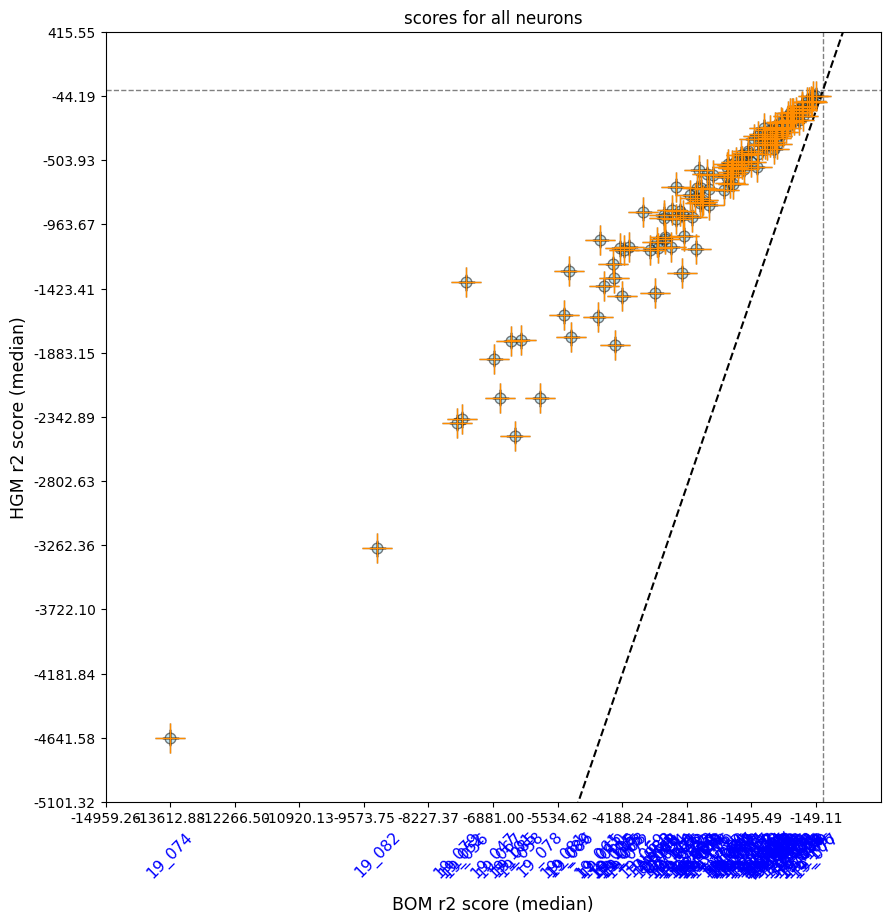

In [9]:
if 'gcamp' in data_variants:
	plot_utils.plot_performance_plot(
		neuron_scores_gcamp, None,
		title='scores for all neurons', limits=None, force_medians=True
	)

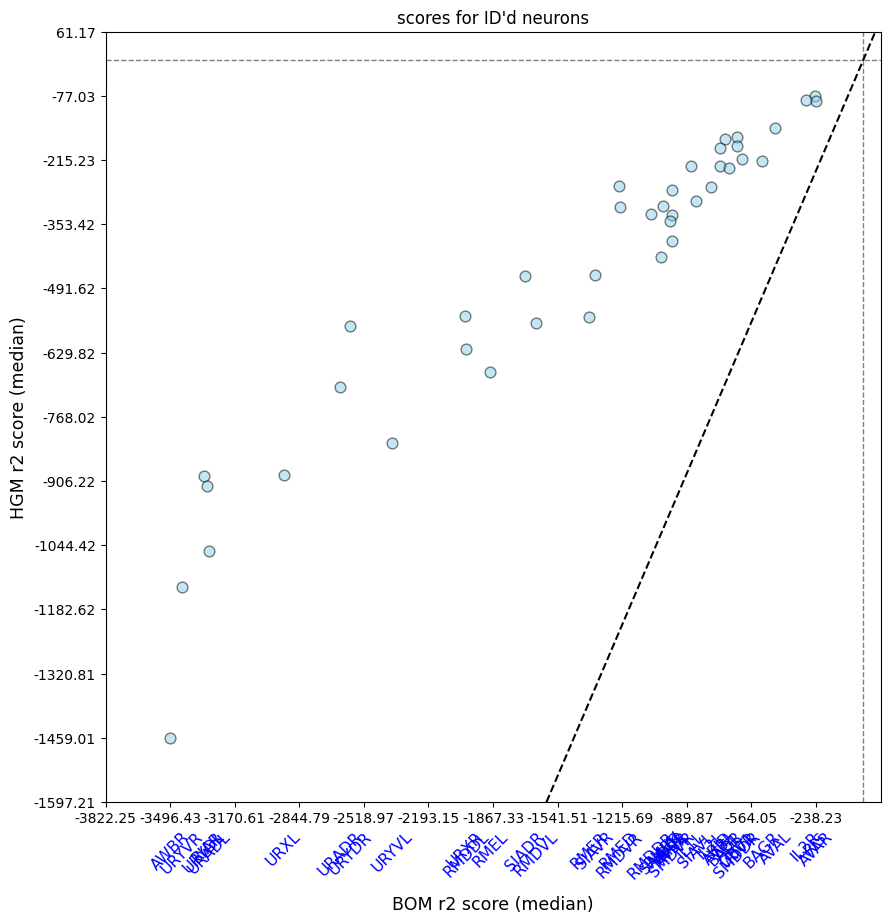

In [10]:
if 'gcamp' in data_variants:
	plot_utils.plot_performance_plot(
		{key: neuron_scores_gcamp[key] for key in neuron_scores_gcamp.keys() if not key[0].isdigit()}, None,
		title='scores for ID\'d neurons', limits=None
	)

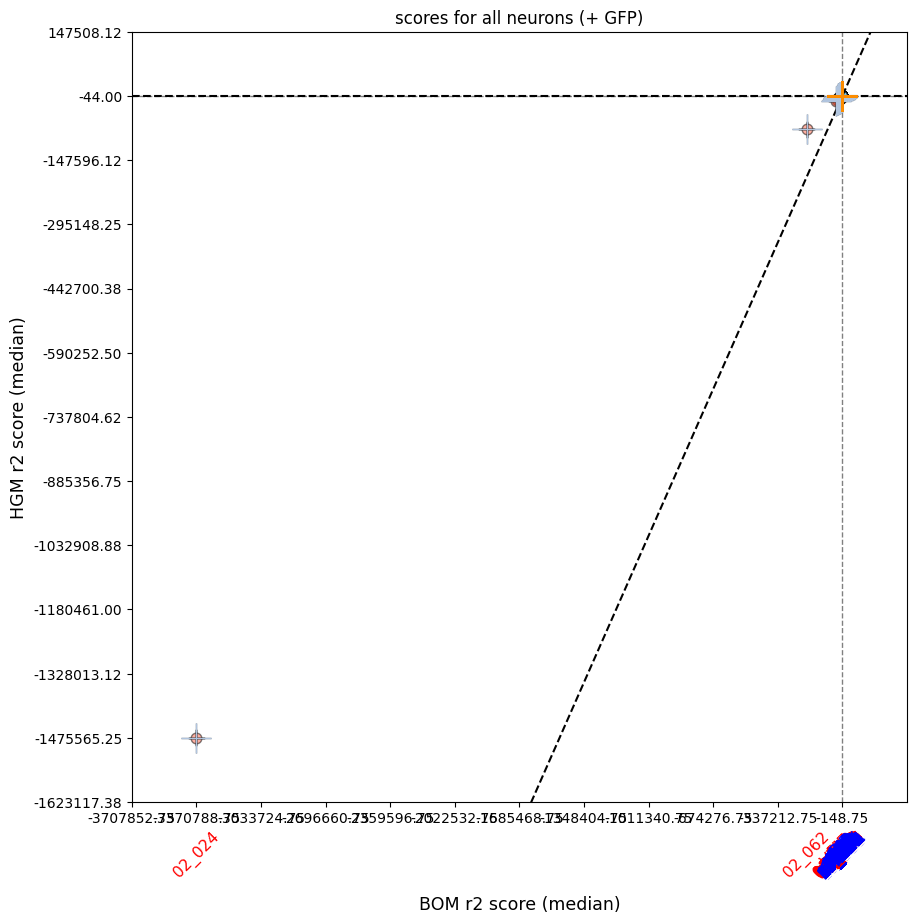

In [11]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	plot_utils.plot_performance_plot(
		neuron_scores_gcamp, neuron_scores_gfp,
		title='scores for all neurons (+ GFP)', limits=None, force_medians=True
	)

In [12]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	threshold_hgm_gfp = np.quantile(np.concatenate([pair[1] for pair in neuron_scores_gfp.values()]), 0.95)

	significant_hgm_n_gcamp = list()
	for key in neuron_scores_gcamp.keys():
		scores_bom, scores_hgm = neuron_scores_gcamp[key]
		if len(scores_hgm.shape) == 0:
			scores_bom = scores_bom.reshape(1, 1)
			scores_hgm = scores_hgm.reshape(1, 1)
		y = np.median(scores_hgm)
		if y > threshold_hgm_gfp:
			significant_hgm_n_gcamp.append(key)

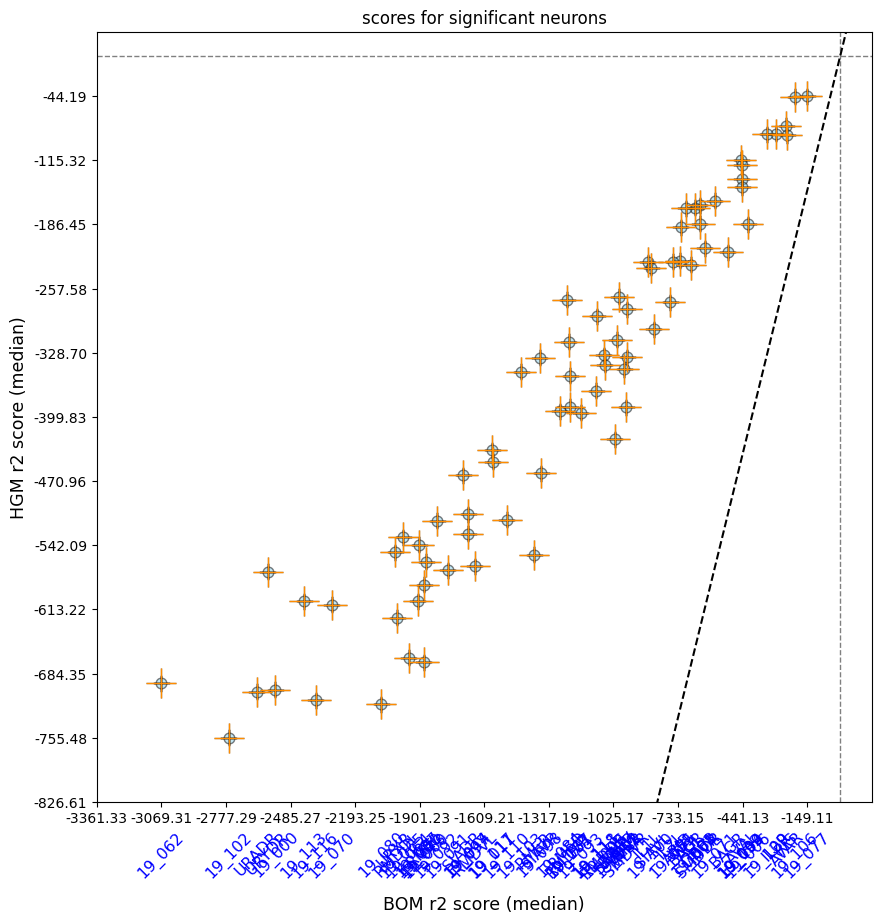

In [13]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	plot_utils.plot_performance_plot(
		{key: neuron_scores_gcamp[key] for key in significant_hgm_n_gcamp}, None,
		title='scores for significant neurons', limits=None, force_medians=True
	)

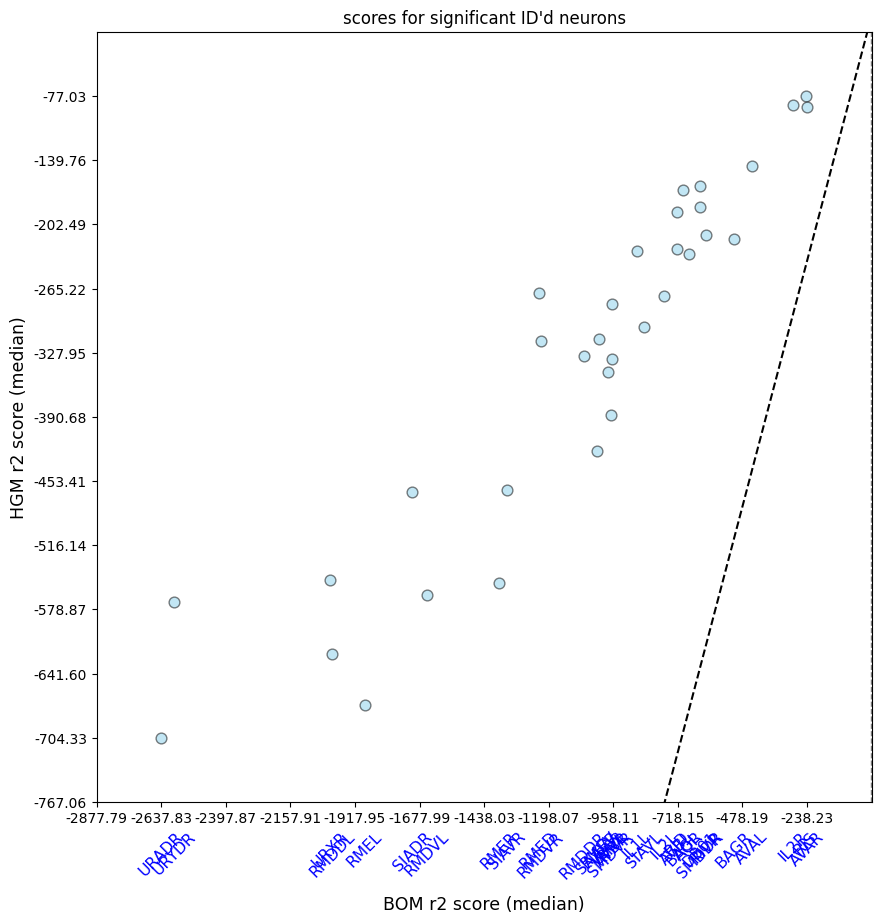

In [14]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	plot_utils.plot_performance_plot(
		{key: neuron_scores_gcamp[key] for key in significant_hgm_n_gcamp if not key[0].isdigit()}, None,
		title='scores for significant ID\'d neurons', limits=None
	)

In [15]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	print('\n'.join([f'NEURON: {key},\tHGM: {np.median(val[1]):.4f}\tBOM: {np.median(val[0]):.4f}' for key, val in reversed(sorted(neuron_scores_gcamp.items(), key=lambda x: np.median(x[1][1]))) if key in significant_hgm_n_gcamp and not key[0].isdigit()]))

NEURON: RIS,	HGM: -77.0274	BOM: -243.3857
NEURON: IL2R,	HGM: -86.2509	BOM: -290.4979
NEURON: AVAR,	HGM: -87.7788	BOM: -238.2315
NEURON: AVAL,	HGM: -145.3565	BOM: -443.2507
NEURON: SMDDR,	HGM: -165.3114	BOM: -634.5386
NEURON: BAGL,	HGM: -168.6186	BOM: -697.7381
NEURON: DB01,	HGM: -185.5807	BOM: -634.8966
NEURON: RID,	HGM: -189.9494	BOM: -721.9039
NEURON: RIVR,	HGM: -212.9765	BOM: -612.5910
NEURON: BAGR,	HGM: -217.1311	BOM: -509.0754
NEURON: AVBL,	HGM: -226.7896	BOM: -723.2839
NEURON: IL1L,	HGM: -228.5585	BOM: -869.9821
NEURON: AQR,	HGM: -231.3992	BOM: -675.5709
NEURON: RMED,	HGM: -269.9753	BOM: -1234.0573
NEURON: IL2L,	HGM: -272.6845	BOM: -768.6348
NEURON: AVBR,	HGM: -280.4856	BOM: -962.4708
NEURON: SIAVL,	HGM: -302.9102	BOM: -843.8558
NEURON: RMEV,	HGM: -314.5512	BOM: -1010.6696
NEURON: RMDVR,	HGM: -316.4467	BOM: -1227.5099
NEURON: RMDDR,	HGM: -331.6259	BOM: -1068.2651
NEURON: RIVL,	HGM: -333.8961	BOM: -962.2223
NEURON: VB02,	HGM: -347.2671	BOM: -976.1871
NEURON: SMDVR,	HGM: -388.9590	

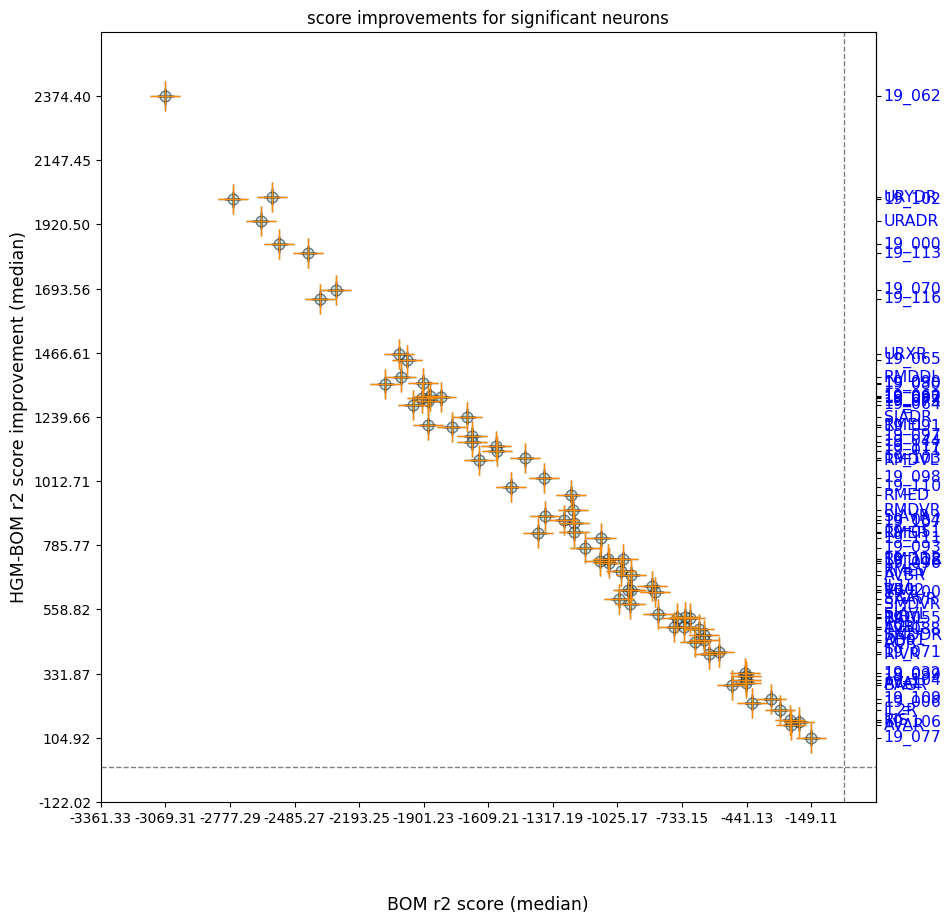

In [16]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	plot_utils.plot_improvement_plot(
		{key: neuron_scores_gcamp[key] for key in significant_hgm_n_gcamp},
		title='score improvements for significant neurons', limits=None, force_medians=True
	)

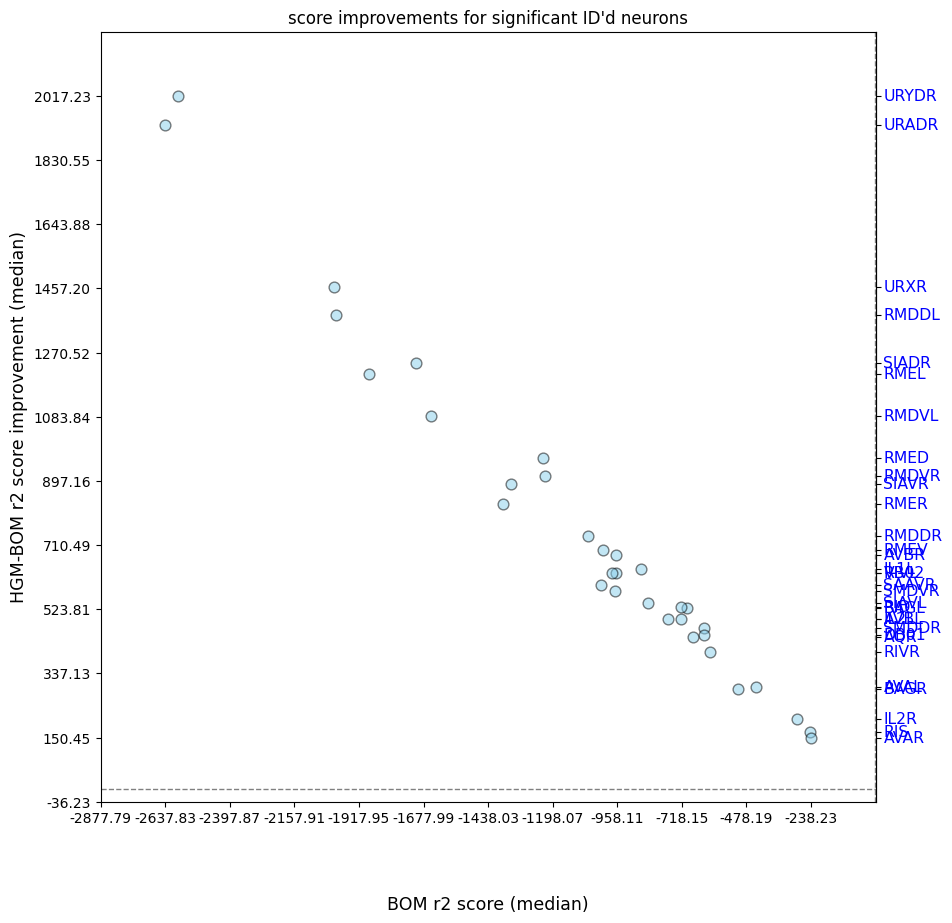

In [17]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	plot_utils.plot_improvement_plot(
		{key: neuron_scores_gcamp[key] for key in significant_hgm_n_gcamp if not key[0].isdigit()}, None,
		title='score improvements for significant ID\'d neurons', limits=None
	)

In [18]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	print('\n'.join([f'NEURON: {key},\tIMPR: {np.median(val[1] - val[0]):.4f}' for key, val in reversed(sorted(neuron_scores_gcamp.items(), key=lambda x: np.median(x[1][1] - x[1][0]))) if key in significant_hgm_n_gcamp and not key[0].isdigit()]))

NEURON: URYDR,	IMPR: 2017.2307
NEURON: URADR,	IMPR: 1933.5067
NEURON: URXR,	IMPR: 1460.8647
NEURON: RMDDL,	IMPR: 1381.0730
NEURON: SIADR,	IMPR: 1240.3444
NEURON: RMEL,	IMPR: 1209.7546
NEURON: RMDVL,	IMPR: 1086.1870
NEURON: RMED,	IMPR: 964.0820
NEURON: RMDVR,	IMPR: 911.0632
NEURON: SIAVR,	IMPR: 889.2623
NEURON: RMER,	IMPR: 830.2286
NEURON: RMDDR,	IMPR: 736.6392
NEURON: RMEV,	IMPR: 696.1183
NEURON: AVBR,	IMPR: 681.9852
NEURON: IL1L,	IMPR: 641.4235
NEURON: VB02,	IMPR: 628.9200
NEURON: RIVL,	IMPR: 628.3262
NEURON: SAAVR,	IMPR: 593.7546
NEURON: SMDVR,	IMPR: 577.3189
NEURON: SIAVL,	IMPR: 540.9456
NEURON: RID,	IMPR: 531.9546
NEURON: BAGL,	IMPR: 529.1195
NEURON: AVBL,	IMPR: 496.4943
NEURON: IL2L,	IMPR: 495.9503
NEURON: SMDDR,	IMPR: 469.2272
NEURON: DB01,	IMPR: 449.3159
NEURON: AQR,	IMPR: 444.1717
NEURON: RIVR,	IMPR: 399.6145
NEURON: AVAL,	IMPR: 297.8942
NEURON: BAGR,	IMPR: 291.9443
NEURON: IL2R,	IMPR: 204.2470
NEURON: RIS,	IMPR: 166.3583
NEURON: AVAR,	IMPR: 150.4527
